In [3]:
import tensorflow as tf
import numpy as np
import sys

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("tf.keras path:", tf.keras.__file__)


Python version: 3.10.3 (tags/v3.10.3:a342a49, Mar 16 2022, 13:07:40) [MSC v.1929 64 bit (AMD64)]
TensorFlow version: 2.13.0
NumPy version: 1.24.3
tf.keras path: d:\predictions\venv\lib\site-packages\keras\api\_v2\keras\__init__.py


In [4]:
import os

DATASET_PATH = "../dataset"  # relative to notebooks/

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Classes:", os.listdir(DATASET_PATH))

for cls in os.listdir(DATASET_PATH):
    cls_path = os.path.join(DATASET_PATH, cls)
    print(cls, "images:", len(os.listdir(cls_path)))


Dataset exists: True
Classes: ['Healthy', 'Parkinson']
Healthy images: 1632
Parkinson images: 1632


In [5]:
TRAIN_DIR = "../dataset_split/train"
VAL_DIR = "../dataset_split/val"

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(224,224),
    batch_size=16,
    shuffle=True
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    VAL_DIR,
    image_size=(224,224),
    batch_size=16,
    shuffle=False
)

print("Class order:", train_ds.class_names)


Found 2610 files belonging to 2 classes.
Found 326 files belonging to 2 classes.
Class order: ['Healthy', 'Parkinson']


In [6]:
print("Class order used in training:", train_ds.class_names)


Class order used in training: ['Healthy', 'Parkinson']


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)


In [8]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])


In [9]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),   # 👈 THIS FIXES IT
    data_augmentation,
    layers.Rescaling(1./255),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(2, activation='softmax')
])

model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 rescaling (Rescaling)       (None, 224, 224, 3)       0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense (Dense)               (None, 128)               163968    
                                                                 
 dropout (Dropout)           (None, 128)              

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [11]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)


Epoch 1/15
164/164 [==============================] - 127s 579ms/step - loss: 0.6323 - accuracy: 0.6667 - val_loss: 0.4761 - val_accuracy: 0.7730
Epoch 2/15
164/164 [==============================] - 92s 563ms/step - loss: 0.4833 - accuracy: 0.7552 - val_loss: 0.4263 - val_accuracy: 0.8190
Epoch 3/15
164/164 [==============================] - 102s 626ms/step - loss: 0.4457 - accuracy: 0.7958 - val_loss: 0.4094 - val_accuracy: 0.8374
Epoch 4/15
164/164 [==============================] - 94s 576ms/step - loss: 0.4192 - accuracy: 0.8092 - val_loss: 0.3942 - val_accuracy: 0.8190
Epoch 5/15
164/164 [==============================] - 95s 578ms/step - loss: 0.4003 - accuracy: 0.8130 - val_loss: 0.3769 - val_accuracy: 0.8344
Epoch 6/15
164/164 [==============================] - 95s 577ms/step - loss: 0.3601 - accuracy: 0.8414 - val_loss: 0.3651 - val_accuracy: 0.8558
Epoch 7/15
164/164 [==============================] - 88s 536ms/step - loss: 0.3660 - accuracy: 0.8307 - val_loss: 0.3666 - val_

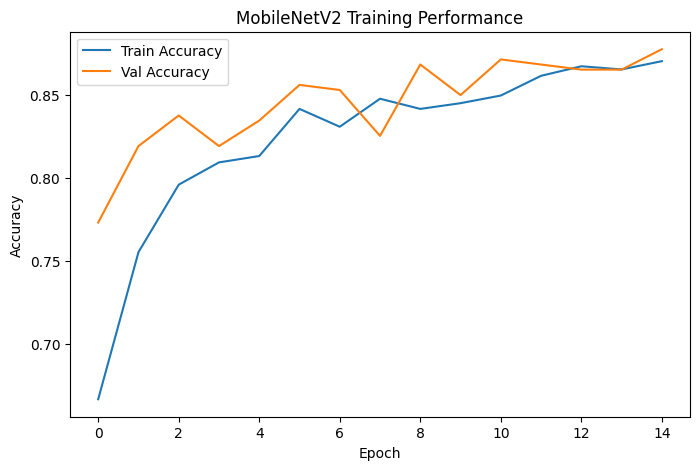

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("MobileNetV2 Training Performance")
plt.show()


In [13]:
MODEL_PATH = "../parkinsons_handwriting_model.keras"

model.save(MODEL_PATH)
print("✅ Model saved as:", MODEL_PATH)


✅ Model saved as: ../parkinsons_handwriting_model.keras


In [14]:
TEST_DIR = "../dataset_split/test"

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TEST_DIR,
    image_size=(224,224),
    batch_size=16,
    shuffle=False
)

test_loss, test_acc = model.evaluate(test_ds)
print("TEST accuracy:", test_acc)


Found 328 files belonging to 2 classes.
21/21 [==============================] - 11s 451ms/step - loss: 0.3022 - accuracy: 0.8628
TEST accuracy: 0.8628048896789551
